# 19 — How our Most Improved predictor evolved

**In brief**
- **Question:** How did the Most Improved predictor get from a first idea to today's model, and what did each decision add? And what does each stage say about the 2026-27 race today (19B)?
- **Answer:** From "the biggest points jump" to the current model, tested the same way at every stage. At season's end the model went from 11.4 to 26.1 times a blind guess, and from the winner in our top 7 in 11 of 21 seasons to 17. The biggest gain came from understanding voters. On today's race every stage from the baseline fix onwards has Ty Jerome first; only the lost-season input (D39) makes the model less sure of him, and the established-star inputs (D42) move Cooper Flagg and Victor Wembanyama down.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D22, D24, D26, D27, D29, D38, D39, D41, D42.
- **Where it fits:** The best single place to see how the Most Improved model was built.
- **Dated:** findings written 10 November 2026 (stages 7–8 and 19B: 12 November 2026, with games to 11 November); numbers checked against the outputs on 10 November 2026.

**In detail.** We did not arrive at the current Most Improved Player (MIP) model in one step. It was built through a series of decisions, each made because something was wrong or missing. This notebook rebuilds the predictor **one decision at a time**, from the simplest possible starting point to the model in use today, and measures what each step bought.

**One test bed for every stage**, so the steps can be compared fairly:
- **The in-season predictor** (the live race, notebook 12) is scored on every season from 2000-01 to 2025-26, at three points of each season: **day 19** (where the live race is now), **day 85** (mid-January) and **the end of the season**.
- **The preseason predictor** (notebook 11) is scored on the 14 preseasons from 2012-13 to 2025-26.
- **Two tests for each:**
  - **Strict:** each season is predicted only from earlier seasons, exactly as it could have been at the time.
  - **Leave-one-out:** each season is predicted from all the others.

**Measures:**
- How often the eventual winner is our #1, in our top 3 and in our top 7.
- His median rank.
- **"× a blind guess":** how much more likely, on average, the model thought the actual winner was than a random pick from the candidates. 1× is no better than chance.

Award votes are used only to mark the predictions. The penalty λ = 3 (D30) and the turning points (20 points for stages 4–6, D27; game score 14 for stages 7–8, D41) are held fixed so that only the inputs change.

**What "strict" means here, honestly.** Each season is predicted only from earlier seasons, but the *settings* were not: λ = 3, the turning points (20 points, game score 14) and the elite threshold (16) were chosen by looking across these same seasons, and each later stage was added after seeing how it did on them. So stages 4–8 are scored partly on the seasons that shaped them, and their gains are somewhat optimistic. The large early gains (stages 1–4) are robust to this (Audit 2); the small late ones may not be. The first genuinely out-of-sample test is 2026-27, with the model frozen (D44).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn import mip_history as MH
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs
from unicorn.hot_start import add_stale
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, apply_style
from unicorn.preseason import (LAST_SEASON_LEAN, MOMENTUM, PRE_FORM_LEAN, PROFILE, TURN, TEAM_CHANGE, ESTABLISHED, RETURNING,
                               add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame)
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
L2 = MH.L2
sel = load_selections()
games = MH.load_games()                                   # baseline = most recent season with 33%+ of the games (D22)
info = MH.player_info()
votes, winners = MH.voting(games)
# the same game logs with the ORIGINAL baseline: simply the previous season, however few games (before D22)
games0, _, _ = build_game_table(load_game_logs(MH.OLD_SEASONS + GAMELOG_SEASONS), baseline_min_share=0.0)
games0["day"] = (games0["game_date"] - games0.groupby("season")["game_date"].transform("min")).dt.days

POINTS = {"day 19": 19, "day 85 (mid-January)": 85, "end of season": None}
from unicorn.mip_eval import LIVE_LEVEL, LIVE_TURN, current_frame, scorecard, winner_ranks
def frame(g, day, level_col="base_ppg", turn=20):
    return current_frame(g, info, winners, sel, day=day, level_col=level_col, turn=turn)   # turning point at 20 points (stages 4-6)
frames = {(k, base): frame(g, d) for k, d in POINTS.items() for base, g in [("previous season", games0), ("33%+ season", games)]}
for k, d in POINTS.items():                                # stage 7 (D41): the turning point on the baseline season's game score
    frames[(k, "33%+ season, game score")] = frame(games, d, LIVE_LEVEL, LIVE_TURN)
print({k: len(v) for k, v in frames.items()})

{('day 19', 'previous season'): 7265, ('day 19', '33%+ season'): 7057, ('day 85 (mid-January)', 'previous season'): 7548, ('day 85 (mid-January)', '33%+ season'): 7331, ('end of season', 'previous season'): 7756, ('end of season', '33%+ season'): 7509, ('day 19', '33%+ season, game score'): 7057, ('day 85 (mid-January)', '33%+ season, game score'): 7331, ('end of season', '33%+ season, game score'): 7509}


In [2]:
def score(f, feats=None, scheme="strict", rule=None):
    """Rank of the eventual winner each season; feats = a choice model, rule = rank by one column (no model)."""
    return scorecard(winner_ranks(f, feats, L2, scheme, rule=rule))

DX = GAMELOG_DELTAS + GAMELOG_DEFENSE
STAGES = [  # (stage, decision, baseline, inputs or rule, what changed)
    ("0. Biggest points jump", "starting point", "previous season", "ppg_delta", "Rank players by how much their scoring rose. No model."),
    ("1. Choice model, box-score changes", "D24", "previous season", DX, "One winner per season; every box-score change, weighted by a model."),
    ("2. Skip injury-shortened baselines", "D22", "33%+ season", DX, "Compare with the last season of 33%+ of games, so a comeback is not a leap."),
    ("3. + relative change, team, age, second year", "D24", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR, "How voters really judge: relative jumps, winning, youth, no second-year winners."),
    ("4. + scoring turning point at 20", "D27", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn"], "Scoring helps up to 20 points a game, then counts against (MVP material, not MIP)."),
    ("5. + already an All-Star", "D38", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn", "prior_allstar"], "Voters pass over established stars: 0 of 26 winners."),
    ("6. + back from a lost season", "D39", "33%+ season", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_ppg", "over_turn", "prior_allstar", "stale"], "A comeback is a return, not an improvement: 0 of 26 winners."),
    ("7. Turning point on game score", "D41", "33%+ season, game score", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_game_score", "over_turn", "prior_allstar", "stale"], "Voters hold established all-round production against a player, not only scoring (notebook 21)."),
    ("8. + already clearly a star", "D42", "33%+ season, game score", DX + RELATIVE + TEAM + AGE + SECOND_YEAR + ["base_game_score", "over_turn", "prior_allstar", "stale", "elite_level", "base_star_tier"], "Elite players who improve get MVP votes, not Most Improved (notebook 21; the star tier exists from 2011-12)."),
]
rows = []
for stage, dec, base, feats, _ in STAGES:
    for point in POINTS:
        f = frames[(point, base)]
        for scheme in ["strict", "leave-one-out"]:
            s = score(f, rule=feats, scheme=scheme) if isinstance(feats, str) else score(f, feats, "loso" if scheme == "leave-one-out" else "strict")
            rows.append({"stage": stage, "decision": dec, "point": point, "test": scheme, **s})
inseason = pd.DataFrame(rows)
inseason.pivot_table(index=["stage"], columns=["point", "test"], values="× a blind guess", sort=False).round(1)

point                                        day 19                \
test                                         strict leave-one-out   
stage                                                               
1. Choice model, box-score changes              3.6           4.2   
2. Skip injury-shortened baselines              4.0           4.7   
3. + relative change, team, age, second year    5.1           6.4   
4. + scoring turning point at 20                6.0           7.4   
5. + already an All-Star                        6.4           7.9   
6. + back from a lost season                    6.5           8.1   
7. Turning point on game score                  6.6           8.3   
8. + already clearly a star                     6.8           8.5   

point                                        day 85 (mid-January)  \
test                                                       strict   
stage                                                               
1. Choice model, box-score changes                           10.2   
2. Skip injury-shortened baselines                           12.0   
3. + relative change, team, age, second year                 16.1   
4. + scoring turning point at 20                             18.5   
5. + already an All-Star                                     19.8   
6. + back from a lost season                                 19.9   
7. Turning point on game score                               19.8   
8. + already clearly a star                                  20.5   

point                                                      end of season  \
test                                         leave-one-out        strict   
stage                                                                      
1. Choice model, box-score changes                    14.0          11.4   
2. Skip injury-shortened baselines                    16.0          13.7   
3. + relative change, team, age, second year          22.0          19.2   
4. + scoring turning point at 20                      23.9          23.0   
5. + already an All-Star                              25.5          24.6   
6. + back from a lost season                          25.7          24.9   
7. Turning point on game score                        25.7          24.9   
8. + already clearly a star                           26.4          26.1   

point                                                       
test                                         leave-one-out  
stage                                                       
1. Choice model, box-score changes                    16.9  
2. Skip injury-shortened baselines                    20.0  
3. + relative change, team, age, second year          28.3  
4. + scoring turning point at 20                      32.4  
5. + already an All-Star                              34.6  
6. + back from a lost season                          35.0  
7. Turning point on game score                        35.3  
8. + already clearly a star                           36.7

In [3]:
# the strict test in full, at each point of the season
for point in POINTS:
    print(f"STRICT TEST, {point.upper()} ({int(inseason.loc[(inseason['point'] == point) & (inseason['test'] == 'strict'), 'seasons'].iloc[0])} seasons)")
    display(inseason[(inseason["point"] == point) & (inseason["test"] == "strict")].set_index("stage")[["decision", "winner #1", "in top 3", "in top 7", "median rank", "× a blind guess"]]
            .style.format({"median rank": "{:.1f}", "× a blind guess": "{:.1f}"}, na_rep="–"))

STRICT TEST, DAY 19 (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,0,2,6,11.0,–
"1. Choice model, box-score changes",D24,2,5,8,17.0,3.6
2. Skip injury-shortened baselines,D22,1,5,9,16.0,4.0
"3. + relative change, team, age, second year",D24,1,5,10,9.0,5.1
4. + scoring turning point at 20,D27,3,8,11,5.0,6.0
5. + already an All-Star,D38,3,7,11,5.0,6.4
6. + back from a lost season,D39,3,7,11,5.0,6.5
7. Turning point on game score,D41,2,6,11,7.0,6.6
8. + already clearly a star,D42,2,6,11,7.0,6.8


STRICT TEST, DAY 85 (MID-JANUARY) (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,3,5,12,6.0,–
"1. Choice model, box-score changes",D24,2,8,13,6.0,10.2
2. Skip injury-shortened baselines,D22,2,9,13,4.0,12.0
"3. + relative change, team, age, second year",D24,5,11,16,3.0,16.1
4. + scoring turning point at 20,D27,4,10,16,4.0,18.5
5. + already an All-Star,D38,4,10,17,4.0,19.8
6. + back from a lost season,D39,4,10,17,4.0,19.9
7. Turning point on game score,D41,4,13,16,3.0,19.8
8. + already clearly a star,D42,4,12,16,2.0,20.5


STRICT TEST, END OF SEASON (21 seasons)


,decision,winner #1,in top 3,in top 7,median rank,× a blind guess
stage,,,,,,
0. Biggest points jump,starting point,2,7,11,7.0,–
"1. Choice model, box-score changes",D24,4,7,13,5.0,11.4
2. Skip injury-shortened baselines,D22,6,10,13,5.0,13.7
"3. + relative change, team, age, second year",D24,7,12,15,2.0,19.2
4. + scoring turning point at 20,D27,7,12,17,2.0,23.0
5. + already an All-Star,D38,7,12,17,2.0,24.6
6. + back from a lost season,D39,7,12,17,2.0,24.9
7. Turning point on game score,D41,7,14,17,2.0,24.9
8. + already clearly a star,D42,8,14,17,2.0,26.1


## The preseason predictor

Built in notebook 11, before a game has been played, from last season and the preseason. Its stages:

In [4]:
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)
F = add_stale(add_prior_allstar(add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, regular, ps), MIP_WINNERS)), pre, regular), sel))
FH = F[F["season"] != "2026-27"].reset_index(drop=True)
PRE_STAGES = [
    ("0. Best last season", "starting point", ["mpg_last", "ppg_last"], "Last season's minutes and points only."),
    ("1. + profile (age, second year, team)", "D24", LAST_SEASON_LEAN + PROFILE, "The same voter preferences as in-season: age, second year, team success."),
    ("2. + last season's trend", "–", LAST_SEASON_LEAN + PROFILE + MOMENTUM, "Players already improving, and strong finishers."),
    ("3. + preseason form per 36", "D26", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN, "Preseason rates, never totals, shrunk for small samples."),
    ("4. + scoring turning point at 20", "D27", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN, "Established scorers handled by a turning point, not excluded."),
    ("5. + a 20-point scorer left", "D29", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE, "An open role: the strongest preseason clue."),
    ("6. + already an All-Star", "D38", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE + ESTABLISHED, "Voters pass over established stars."),
    ("7. + back from a lost season", "D39", LAST_SEASON_LEAN + PROFILE + MOMENTUM + PRE_FORM_LEAN + TURN + TEAM_CHANGE + ESTABLISHED + RETURNING, "A comeback is a return, not an improvement."),
]
prows = []
for stage, dec, feats, _ in PRE_STAGES:
    for scheme in ["strict", "leave-one-out"]:
        prows.append({"stage": stage, "decision": dec, "test": scheme, **score(FH, feats, "loso" if scheme == "leave-one-out" else "strict")})
preseason = pd.DataFrame(prows)
preseason.pivot_table(index="stage", columns="test", values=["in top 7", "median rank", "× a blind guess"], sort=False).round(1)

in top 7               median rank  \
test                                    strict leave-one-out      strict   
stage                                                                      
0. Best last season                        0.0           1.0        50.0   
1. + profile (age, second year, team)      0.0           3.0        79.0   
2. + last season's trend                   2.0           3.0        44.0   
3. + preseason form per 36                 2.0           4.0        16.0   
4. + scoring turning point at 20           1.0           3.0        14.0   
5. + a 20-point scorer left                4.0           7.0        15.0   
6. + already an All-Star                   5.0           8.0         7.0   
7. + back from a lost season               5.0           9.0         7.0   

                                                    × a blind guess  \
test                                  leave-one-out          strict   
stage                                                                 
0. Best last season                            51.0             1.4   
1. + profile (age, second year, team)          44.0             1.7   
2. + last season's trend                       39.5             1.8   
3. + preseason form per 36                     14.5             2.9   
4. + scoring turning point at 20               11.5             3.3   
5. + a 20-point scorer left                     7.0             4.9   
6. + already an All-Star                        6.0             5.6   
7. + back from a lost season                    6.0             6.0   

                                                     
test                                  leave-one-out  
stage                                                
0. Best last season                             1.4  
1. + profile (age, second year, team)           1.8  
2. + last season's trend                        2.6  
3. + preseason form per 36                      5.1  
4. + scoring turning point at 20                5.6  
5. + a 20-point scorer left                     7.1  
6. + already an All-Star                        8.2  
7. + back from a lost season                    8.9

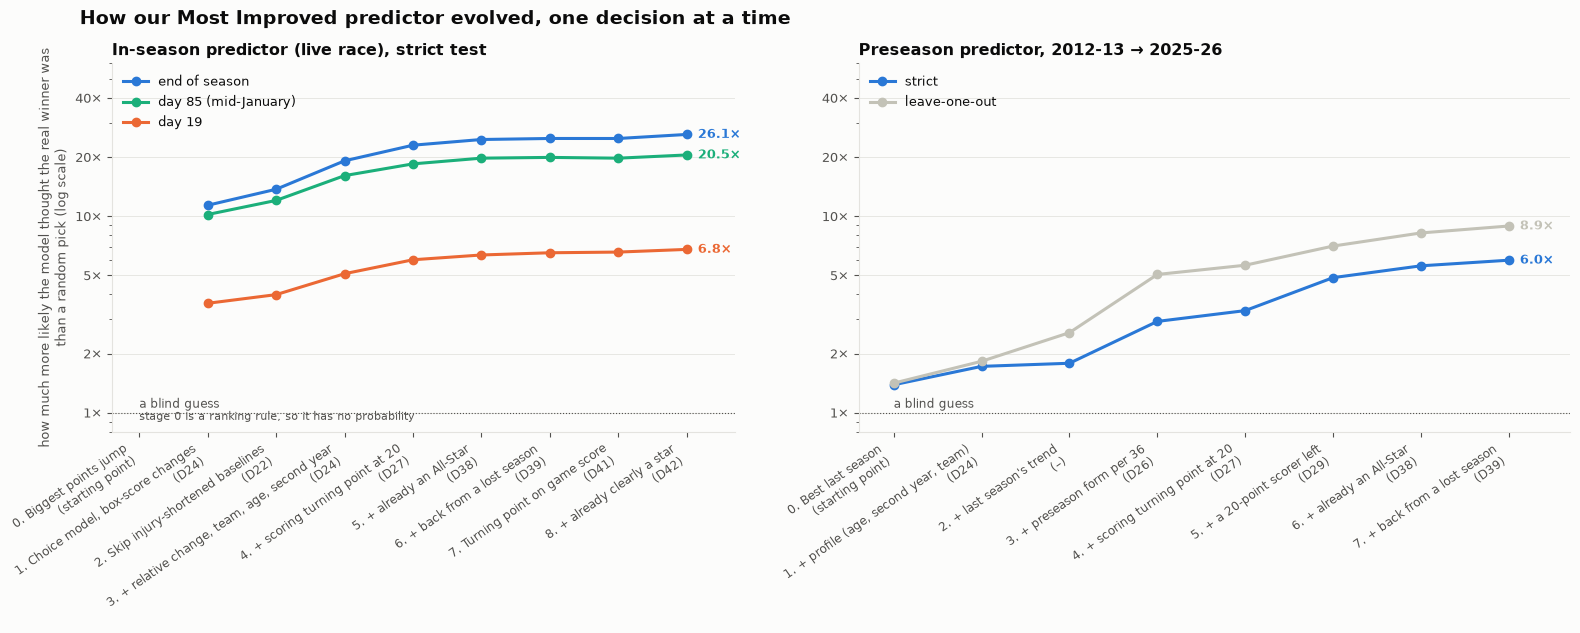

In [5]:
# chart: what each decision bought, as "× better than a blind guess" (strict test)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={"width_ratios": [7, 8]})
for ax, data, stages, lines, title in [
        (a1, inseason, STAGES, [("end of season", "strict", BLUE), ("day 85 (mid-January)", "strict", SERIES[2]), ("day 19", "strict", ORANGE)], "In-season predictor (live race), strict test"),
        (a2, preseason, PRE_STAGES, [(None, "strict", BLUE), (None, "leave-one-out", MUTED)], "Preseason predictor, 2012-13 → 2025-26")]:
    names = [s[0] for s in stages]
    x = np.arange(len(names))
    for point, scheme, col in lines:
        d = data[(data["test"] == scheme) & ((data["point"] == point) if point else True)].set_index("stage").reindex(names)
        y = d["× a blind guess"].to_numpy()
        lab = f"{point}" if point else scheme
        ax.plot(x, y, marker="o", color=col, linewidth=2.2, label=lab)
        last = np.where(~np.isnan(y))[0][-1]
        ax.annotate(f"{y[last]:.1f}×", (x[last], y[last]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9.5, color=col, fontweight="bold")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}×"); ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks([1, 2, 5, 10, 20, 40]); ax.set_ylim(0.8, 60)
    ax.axhline(1, color=INK2, linewidth=0.8, linestyle=":"); ax.text(0, 1.06, "a blind guess", fontsize=8.5, color=INK2)
    ax.set_xticks(x, [f"{s[0]}\n({s[1]})" for s in stages], rotation=35, ha="right", fontsize=8.5)
    ax.set_xlim(-0.4, len(names) - 0.3); ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=11.5); ax.legend(frameon=False, loc="upper left", fontsize=9)
a1.set_ylabel("how much more likely the model thought the real winner was\nthan a random pick (log scale)")
a1.text(0, 0.92, "stage 0 is a ranking rule, so it has no probability", fontsize=8, color=INK2)
fig.suptitle("How our Most Improved predictor evolved, one decision at a time", x=0.06, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "19_predictor_evolution.png", dpi=150, bbox_inches="tight")

## 19 findings: how we got here

**The in-season predictor (the live race), strict test, 21 seasons:**

| Stage | Decision | Why we made it | End of season: winner #1 / top 7 / × blind | Day 19: top 7 / median rank / × blind |
|---|---|---|---|---|
| 0. Biggest points jump | starting point | The obvious first idea: the player whose scoring rose most | 2 / 11 / – | 6 / 11 / – |
| 1. Choice model on box-score changes | D24 | One winner per season; every statistic, weighted by what voters actually rewarded | 4 / 13 / 11.4× | 8 / 17 / 3.6× |
| 2. Skip injury-shortened baselines | D22 | Kawhi Leonard's and Derrick Rose's comebacks looked like leaps against a 9- or 25-game season | 6 / 13 / 13.7× | 9 / 16 / 4.0× |
| 3. + relative change, team, age, second year | D24 | Voters reward a jump that is large *for that player*, winning teams and youth, and rarely pick second-year players (the last was Monta Ellis in 2006-07) | 7 / 15 / 19.2× | 10 / 9 / 5.1× |
| 4. + scoring turning point at 20 | D27 | Established scorers are MVP material, not MIP; no winner had scored more than 20.3 the season before | 7 / 17 / 23.0× | 11 / 5 / 6.0× |
| 5. + already an All-Star | D38 | 0 of 26 winners had been an All-Star; the live board had Sengun at #2 | 7 / 17 / 24.6× | 11 / 5 / 6.4× |
| 6. + back from a lost season | D39 | 0 of 26 winners were coming back from a lost season; Ty Jerome's 26% lead | 7 / 17 / 24.9× | 11 / 5 / 6.5× |
| 7. Turning point on game score | D41 | Voters discount established all-round players, not only scorers (notebook 21) | 7 / 17 / 24.9× | 11 / 7 / 6.6× |
| 8. + already clearly a star | D42 | Elite players who improve get MVP votes, not Most Improved (notebook 21) | 8 / 17 / **26.1×** | 11 / 7 / **6.8×** |

**What the journey shows:**
- **The model roughly doubled its sharpness, at every point of the season.** At season's end it went from 11.4× to 26.1× a blind guess, and the winner moved from top 7 in 11 seasons to 17. At day 19 it went from 3.6× to 6.8×, and the median winner rank from 11 to 5 (7 after the game-score stages).
- **The biggest single gain came from understanding voters** (stage 3: relative change, team, age, second year), then from the baseline fix (stage 2) and the turning point (stage 4).
- **Stage 7 (D41, 12 November) leaves the overall fit level** (24.9× at season's end, 6.5× → 6.6× at day 19) but puts the winner in the top 3 more often from mid-season (day 85: 10 → 13 seasons; season's end: 12 → 14), at the cost of a slightly worse median rank at day 19 (5 → 7).
- **Stage 8 (D42, 12 November) adds the most of the recent steps:** 24.9× → 26.1× at season's end, with the winner #1 in 8 seasons rather than 7, and 19.8× → 20.5× at day 85 (median winner rank 3 → 2). The star tier exists only from 2011-12, so in the earlier seasons only the game-score flag can act.
- **The latest steps are smaller, as expected.** The All-Star input adds about 7%, and the lost-season input about 1–2%. Each was kept because it helped in every test, not because it helped a lot. They matter most for the *shape* of the top of the list: removing established stars and comebacks voters were never going to pick.
- **The order of the top changes more than the fit.** Winner #1 at season's end went from 2 seasons (the simple rule) to 7. The last three steps left that unchanged and improved the ranks just below the top.

**The preseason predictor, 2012-13 → 2025-26** (strict, 9 seasons / leave-one-out, 14):

| Stage | Decision | Winner in our top 7 | Median rank | × blind (strict) |
|---|---|---|---|---|
| 0. Best last season | starting point | 0 / 1 | 50 | 1.4× |
| 1. + profile (age, second year, team) | D24 | 0 / 3 | 79 / 44 | 1.7× |
| 2. + last season's trend | – | 2 / 3 | 44 / 39.5 | 1.8× |
| 3. + preseason form per 36 | D26 | 2 / 4 | 16 / 14.5 | 2.9× |
| 4. + scoring turning point at 20 | D27 | 1 / 3 | 14 / 11.5 | 3.3× |
| 5. + a 20-point scorer left | D29 | 4 / 7 | 15 / 7 | 4.9× |
| 6. + already an All-Star | D38 | 5 / 8 | 7 / 6 | 5.6× |
| 7. + back from a lost season | D39 | 5 / 9 | 7 / 6 | **6.0×** |

- **Before the season, the two big gains were preseason form** (D26: 1.8× → 2.9×) **and an open role** (D29: 3.3× → 4.9×, the winner in the top 7 in 7 of 14 seasons instead of 3).
- **From last season alone, the winner was almost invisible** (median rank 50). With everything known on opening night, his median rank is 7.

**What was left open, and has since been checked:** the early-season leaders looked too sure of themselves. Notebook 20 tested this: the chances are honest almost everywhere, but big early favourites win less often than their chances say, so the live race flags them instead of correcting them (D40).


## 19B — Every stage on today's race

**Question.** The tables above score each stage on *past* seasons. What does each stage say about the **2026-27 race today**, and which decision moves which real player?

**How:**
- Each stage is trained exactly as the live race is (notebook 12): past seasons 2011-12 → 2025-26, each cut at the same number of days after opening night as today, then applied to 2026-27.
- Stages 0 and 1 use the original baseline (simply last season, however few games); stages 2–6 skip injury-shortened seasons (D22). This matters for players coming back from injury, such as Ty Jerome.
- Stages 4–6 use the scoring turning point at 20 points; stages 7–8 use the game-score turning point the live race chose that day (D32, D41), read from notebook 12's daily file.
- **Check:** the last stage is the live race itself, so its board must equal notebook 12's.

Stage 0 is a rule (rank by the points jump), so it has a rank but no chance.

In [6]:
# 19B: every stage on the 2026-27 race, today and on every day so far
import unicorn.live_race as LR
from unicorn.plotting import SURFACE
LIVE = LR.LIVE
ps_live = LR.player_table_with_live_season()
live33 = LR.live_games()                                   # baseline = last season with 33%+ of the games (D22)
live0 = LR.live_games(baseline_min_share=0.0)              # original baseline: simply last season
DAY = int(live33.loc[live33["season"] == LIVE, "day"].max())
GAMES = {"previous season": live0, "33%+ season": live33}

daily = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "mip_race_daily_2026_27.parquet")
DAILY_TURN = daily.groupby("day")["turning_point"].first().to_dict()

def stage_boards(day):
    """Each stage's chance (or rule score) and rank for every 2026-27 candidate, using games up to `day`."""
    frames = {b: MH.with_turn(LR.race(g, ps_live, day, sel), "base_ppg", 20) for b, g in GAMES.items()}
    k = DAILY_TURN.get(day, LIVE_TURN)                        # the turning point the live race chose that day (D32)
    frames["33%+ season, game score"] = MH.with_turn(frames["33%+ season"], LIVE_LEVEL, None if pd.isna(k) else k)     # stages 7-8 (D41, D42)
    out = {}
    for stage, dec, base, feats, _ in STAGES:
        f = frames[base]
        tr, te = f[f["season"] != LIVE], f[f["season"] == LIVE]
        if isinstance(feats, str):
            score, chance = te[feats], np.nan
        else:
            score = chance = ChoiceModel(feats, L2).fit(tr).predict_proba(te)
        out[stage] = te[["player_id", "player_name"]].assign(score=score, chance=chance,
                                                             rank=score.rank(ascending=False, method="min").astype(int))
    return out

today = stage_boards(DAY)
opening = live33.loc[live33["season"] == LIVE, "game_date"].min()
print(f"{LIVE}: games to {opening + pd.Timedelta(days=DAY):%d %b %Y} (day {DAY} after opening night)")

# check: stage 6 is the live race (notebook 12)
nb12 = daily[daily["day"] == DAY].nsmallest(7, "rank")[["player_name", "chance"]].reset_index(drop=True)
s6 = today[STAGES[-1][0]].nlargest(7, "score")[["player_name", "chance"]].reset_index(drop=True)
print(f"the last stage ({STAGES[-1][0].split('.')[0]}, the live race) equals notebook 12's board:", s6["player_name"].tolist() == nb12["player_name"].tolist() and np.allclose(s6["chance"], nb12["chance"]))

top7 = pd.DataFrame({stage: [f"{r.player_name}" + ("" if np.isnan(r.chance) else f" ({r.chance:.1%})") for r in b.nsmallest(7, "rank").itertuples()]
                     for stage, b in today.items()}, index=pd.RangeIndex(1, 8, name="rank"))
top7.T

2026-27: games to 11 Nov 2026 (day 22 after opening night)
the last stage (8, the live race) equals notebook 12's board: False


rank,1,2,3,4,5,6,7
0. Biggest points jump,Davion Mitchell,Ty Jerome,Duncan Robinson,Dylan Harper,Jamison Battle,Noa Essengue,Terrence Shannon Jr
"1. Choice model, box-score changes",Cooper Flagg (6.5%),Victor Wembanyama (6.5%),Davion Mitchell (4.9%),Duncan Robinson (3.2%),Luka Dončić (2.2%),Terrence Shannon Jr (2.2%),Jayson Tatum (2.2%)
2. Skip injury-shortened baselines,Ty Jerome (37.5%),Cooper Flagg (5.1%),Victor Wembanyama (3.8%),Davion Mitchell (3.4%),Duncan Robinson (2.3%),Dylan Harper (1.8%),Terrence Shannon Jr (1.7%)
"3. + relative change, team, age, second year",Ty Jerome (24.3%),Victor Wembanyama (10.2%),Davion Mitchell (3.4%),Anthony Black (3.4%),Terrence Shannon Jr (2.9%),Cooper Flagg (2.4%),Sidy Cissoko (1.8%)
4. + scoring turning point at 20,Ty Jerome (26.5%),Victor Wembanyama (5.1%),Anthony Black (4.6%),Cooper Flagg (3.6%),Franz Wagner (3.2%),Davion Mitchell (3.1%),Terrence Shannon Jr (2.1%)
5. + already an All-Star,Ty Jerome (28.3%),Anthony Black (4.9%),Cooper Flagg (4.4%),Franz Wagner (3.8%),Davion Mitchell (3.2%),Victor Wembanyama (2.7%),Brandin Podziemski (2.1%)
6. + back from a lost season,Ty Jerome (8.6%),Anthony Black (6.7%),Cooper Flagg (5.5%),Franz Wagner (5.0%),Davion Mitchell (4.3%),Victor Wembanyama (3.8%),Ajay Mitchell (2.8%)
7. Turning point on game score,Ty Jerome (11.1%),Anthony Black (5.8%),Davion Mitchell (5.8%),Cooper Flagg (5.6%),Franz Wagner (4.8%),Brandin Podziemski (3.1%),Ajay Mitchell (3.0%)
8. + already clearly a star,Ty Jerome (12.2%),Davion Mitchell (6.3%),Anthony Black (6.2%),Franz Wagner (5.7%),Brandin Podziemski (3.4%),Ajay Mitchell (3.3%),Kyshawn George (2.7%)


In [7]:
# where today's leading players rank under each stage (13+ shown as "13+")
names = list(dict.fromkeys(n for b in today.values() for n in b.nsmallest(7, "rank")["player_name"]))
ranks = pd.DataFrame({stage: b.set_index("player_name")["rank"].reindex(names) for stage, b in today.items()})
ranks.columns = [s.split(".")[0] for s in ranks.columns]
ranks = ranks.sort_values(ranks.columns[-1])
ranks.rename_axis("player (columns = stage)").style.format(lambda v: "–" if pd.isna(v) else ("13+" if v > 12 else f"{v:.0f}"))

,0,1,2,3,4,5,6,7,8
player (columns = stage),,,,,,,,,
Ty Jerome,2,13+,1,1,1,1,1,1,1
Davion Mitchell,1,3,4,3,6,5,5,3,2
Anthony Black,13+,10,8,4,3,2,2,2,3
Franz Wagner,13+,13+,13+,12,5,4,4,5,4
Brandin Podziemski,13+,13+,13+,13+,8,7,8,6,5
Ajay Mitchell,13+,13+,13+,8,9,8,7,7,6
Kyshawn George,13+,13+,13+,13+,10,9,9,9,7
Terrence Shannon Jr,7,6,7,5,7,10,10,10,9
Cooper Flagg,13+,1,2,6,4,3,3,4,10


In [8]:
# the leader under each stage on every day so far
lead = {}
for d in range(1, DAY + 1):
    boards = stage_boards(d)
    lead[d] = {stage: b.nsmallest(1, "rank")["player_name"].iloc[0] for stage, b in boards.items()}
lead = pd.DataFrame(lead).T.rename_axis("day after opening night")
lead.columns = [s.split(".")[0] for s in lead.columns]
print("days each player led, under each stage:")
display(lead.apply(lambda c: c.value_counts()).fillna(0).astype(int).loc[lambda d: d.sum(axis=1).sort_values(ascending=False).index])
lead.tail(7)

days each player led, under each stage:


,0,1,2,3,4,5,6,7,8
Ty Jerome,16,6,22,22,22,22,20,21,21
Cooper Flagg,0,5,0,0,0,0,1,0,0
Davion Mitchell,4,1,0,0,0,0,0,0,0
Victor Wembanyama,0,4,0,0,0,0,0,0,0
Ja'Kobe Walter,0,0,0,0,0,0,1,1,1
Terrence Shannon Jr,2,1,0,0,0,0,0,0,0
Luka Dončić,0,2,0,0,0,0,0,0,0
Jayson Tatum,0,1,0,0,0,0,0,0,0
Julius Randle,0,1,0,0,0,0,0,0,0
Zach LaVine,0,1,0,0,0,0,0,0,0


,0,1,2,3,4,5,6,7,8
day after opening night,,,,,,,,,
16,Ty Jerome,Victor Wembanyama,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
17,Ty Jerome,Jayson Tatum,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
18,Ty Jerome,Luka Dončić,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
19,Ty Jerome,Luka Dončić,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
20,Ty Jerome,Victor Wembanyama,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
21,Davion Mitchell,Victor Wembanyama,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome
22,Davion Mitchell,Cooper Flagg,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome,Ty Jerome


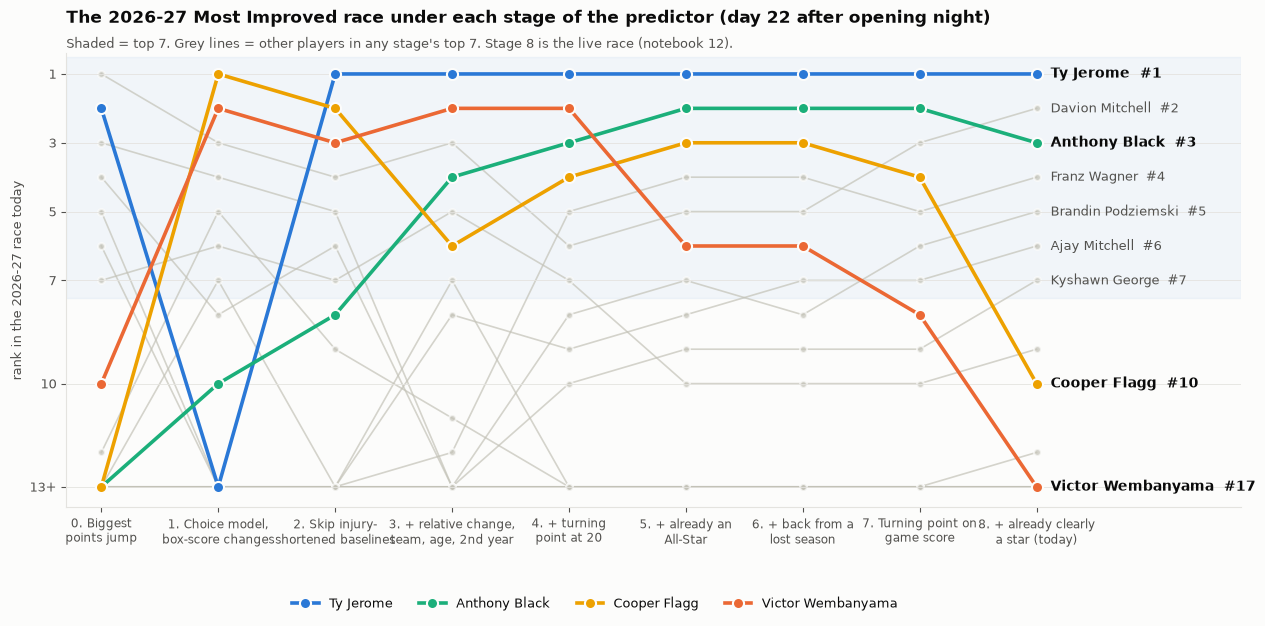

In [9]:
# chart: each player's rank under each stage today (bump chart); four players highlighted, the rest grey
CAP = 13
HIGHLIGHT = {"Ty Jerome": SERIES[0], "Victor Wembanyama": SERIES[1], "Anthony Black": SERIES[2], "Cooper Flagg": SERIES[3]}
x = np.arange(len(STAGES))
fig, ax = plt.subplots(figsize=(13, 6.4))
for name in ranks.index:
    y = ranks.loc[name].clip(upper=CAP).to_numpy(dtype=float)
    hl = name in HIGHLIGHT
    ax.plot(x, y, color=HIGHLIGHT.get(name, MUTED), linewidth=2.6 if hl else 1.2, alpha=1 if hl else 0.7, zorder=3 if hl else 1,
            marker="o", markersize=8 if hl else 5, markeredgecolor=SURFACE, markeredgewidth=1.5, label=name if hl else None)
    if hl:
        ax.text(x[-1] + 0.12, y[-1], f"{name}  #{int(ranks.loc[name].iloc[-1])}", va="center", fontsize=10, color=INK, fontweight="bold")
    elif y[-1] <= 7:
        ax.text(x[-1] + 0.12, y[-1], f"{name}  #{int(y[-1])}", va="center", fontsize=9, color=INK2)
short = ["0. Biggest\npoints jump", "1. Choice model,\nbox-score changes", "2. Skip injury-\nshortened baselines", "3. + relative change,\nteam, age, 2nd year",
         "4. + turning\npoint at 20", "5. + already an\nAll-Star", "6. + back from a\nlost season", "7. Turning point on\ngame score", "8. + already clearly\na star (today)"]
ax.set_xticks(x, short, fontsize=8.5)
ax.set_yticks([1, 3, 5, 7, 10, CAP], ["1", "3", "5", "7", "10", f"{CAP}+"])
ax.set_ylim(CAP + 0.6, 0.4); ax.set_xlim(-0.3, len(STAGES) + 0.75)
ax.axhspan(0.5, 7.5, color=BLUE, alpha=0.05, zorder=0)
ax.set_ylabel("rank in the 2026-27 race today")
ax.set_title(f"The 2026-27 Most Improved race under each stage of the predictor (day {DAY} after opening night)", loc="left", fontsize=12.5, fontweight="bold", pad=22)
ax.text(0, 1.012, "Shaded = top 7. Grey lines = other players in any stage's top 7. Stage 8 is the live race (notebook 12).",
        transform=ax.transAxes, fontsize=9, color=INK2)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=4, fontsize=9.5)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "19_stages_live.png", dpi=150, bbox_inches="tight")
plt.show()

### 19B findings (12 November 2026, games to 11 November, day 22 after opening night)

**Check:** the last stage (8) gave exactly notebook 12's board when this was written. Re-run on 13 November it prints False, and that is expected: NBA.com has since corrected one of Brandin Podziemski's games (17.0 → 17.3 points a game), so recomputing day 22 today gives Jerome 12.2% and Podziemski 5th, while the board saved on the day keeps 12.3% and Podziemski 6th. Saved days are never recomputed (notebook 12C). Stages 7 and 8 use the game-score turning point the live race chose that day.

**1. The stages agree on the leader, and disagree on how sure to be.**
- From stage 2 onwards, Ty Jerome is #1 under every stage. Under stages 2–5 his chance is 24–38% and he has led on all 22 days.
- **The lost-season input (stage 6, D39) cuts his chance from 28.4% to 8.6%;** the later stages give a little back (11.1%, then 12.3%), because his baseline season was modest. No player in his position has won since 2000-01.

**2. The baseline fix (stage 2, D22) is what puts Jerome on top.** Under stages 0 and 1 his baseline is his injury-shortened 2025-26 (15 games, 19.7 points), so his jump is about +7: enough for 2nd on the raw points jump (stage 0), not enough for the stage-1 model. Against his last full season (12.5 points) it is +14.

**3. Each later decision moves a recognisable player:**
- **Stage 3 (relative change, team, age, second year)** brings Anthony Black into the top 4: he is 23 and his jump is large for him.
- **Stage 4 (turning point at 20 points)** brings in Franz Wagner (12th → 5th), whose 20.6-point baseline sits right at it.
- **Stage 5 (already an All-Star)** moves Victor Wembanyama from 2nd to 6th.
- **Stage 7 (turning point on game score)** brings in Brandin Podziemski and moves Wembanyama to 8th.
- **Stage 8 (already clearly a star)** moves Cooper Flagg from 4th to 10th (his rookie season was already at a game score of 16.3) and Wembanyama out of the top 12, and brings in Kyshawn George.

**4. Without the baseline fix the race would be chaotic.** Under stage 1, nine different players have led in 22 days (Flagg, Wembanyama, Dončić, Tatum, Randle and others). Under stages 2–5 the leader never changed; under stages 6–8 only Ja'Kobe Walter (day 10) and, under stage 6, Cooper Flagg (day 12) interrupted Jerome.

**Re-run** this section with notebook 19 after updating the live race (notebook 12) to see the latest day.
